## 1. Install Required Libraries


In [91]:
!pip install -q transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn shap

## 2. Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.metrics import classification_report, multilabel_confusion_matrix, f1_score, precision_score, recall_score, accuracy_score
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding, pipeline

## 3. Upload and Load Dataset

In [93]:
from google.colab import files
uploaded = files.upload()
csv_file = list(uploaded.keys())[0]
df = pd.read_csv(csv_file)

Saving App-Review-Multiclass-Classification.csv to App-Review-Multiclass-Classification (1).csv


In [ ]:
def clean_multilabels(row):
    if row['bug_reports'] == 1:
        return pd.Series([1, 0, 0])
    elif row['features_request'] == 1:
        return pd.Series([0, 1, 0])
    elif row['experience'] == 1:
        return pd.Series([0, 0, 1])
    else:
        return pd.Series([0, 0, 1])

df[['bug_reports', 'features_request', 'experience']] = df.apply(clean_multilabels, axis=1)

## 4. Bar Chart of Classes Distribution

/tmp/ipykernel_8380/1843187841.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='viridis')


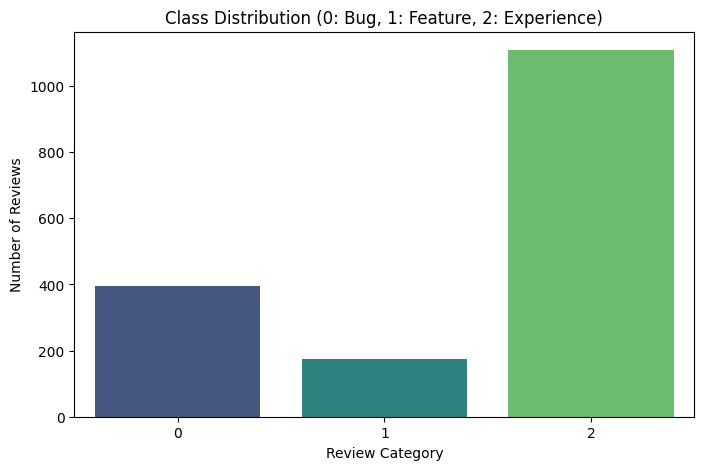

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', palette='viridis')
plt.title('Class Distribution (0: Bug, 1: Feature, 2: Experience)')
plt.xlabel('Review Category')
plt.ylabel('Number of Reviews')
plt.show()


## 5. Preprocessing

In [95]:
import re

def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s'!?.,-]", " ", text)
    text = text.lower()
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    return text.strip()

TEXT_COLUMN = [c for c in df.columns if c not in ['bug_reports','features_request','experience']][0]
df['clean_text'] = df[TEXT_COLUMN].apply(clean_text)

def get_label(row):
    if row['bug_reports'] == 1: return 0
    elif row['features_request'] == 1: return 1
    else: return 2

df['label'] = df.apply(get_label, axis=1)


## 6. Word Counts

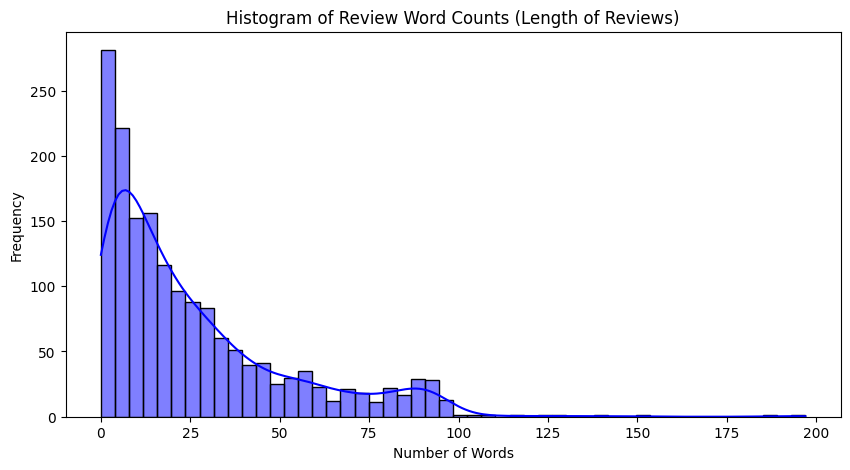

In [107]:
df['word_count'] = df['clean_text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 5))
sns.histplot(df['word_count'], bins=50, kde=True, color='blue')
plt.title('Histogram of Review Word Counts (Length of Reviews)')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()


## 7.  Train / Validation / Test Split

In [96]:
from sklearn.model_selection import train_test_split
from datasets import Dataset
import pandas as pd

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])
train_df, val_df  = train_test_split(train_df, test_size=0.15, random_state=42, stratify=train_df['label'])

dfs_to_concat = [train_df[train_df['label'] == 2]]

bugs = train_df[train_df['label'] == 0]
dfs_to_concat.append(bugs.sample(len(bugs)*2, replace=True, random_state=42))

features = train_df[train_df['label'] == 1]
dfs_to_concat.append(features.sample(len(features)*4, replace=True, random_state=42))

train_df = pd.concat(dfs_to_concat).sample(frac=1, random_state=42).reset_index(drop=True)

def make_hf_dataset(target_dataframe):
    temp = target_dataframe[['clean_text', 'label']].copy()
    return Dataset.from_pandas(temp, preserve_index=False)

train_ds = make_hf_dataset(train_df)
val_ds   = make_hf_dataset(val_df)
test_ds  = make_hf_dataset(test_df)


## 8. Tokenization

In [97]:
from transformers import AutoTokenizer

MODEL_NAMES = ['roberta-base', 'roberta-large']
tokenizers = {name: AutoTokenizer.from_pretrained(name) for name in MODEL_NAMES}

def tokenize(batch, tokenizer):
    tokenized_inputs = tokenizer(batch['clean_text'], truncation=True, max_length=256)
    tokenized_inputs['labels'] = batch['label']
    return tokenized_inputs

train_ds_tok = {name: train_ds.map(lambda x: tokenize(x, tokenizer=tokenizers[name]), batched=True) for name in MODEL_NAMES}
val_ds_tok   = {name: val_ds.map(lambda x: tokenize(x, tokenizer=tokenizers[name]), batched=True) for name in MODEL_NAMES}
test_ds_tok  = {name: test_ds.map(lambda x: tokenize(x, tokenizer=tokenizers[name]), batched=True) for name in MODEL_NAMES}


Map:   0%|          | 0/1769 [00:00<?, ? examples/s]

Map:   0%|          | 0/1769 [00:00<?, ? examples/s]

Map:   0%|          | 0/202 [00:00<?, ? examples/s]

Map:   0%|          | 0/202 [00:00<?, ? examples/s]

Map:   0%|          | 0/336 [00:00<?, ? examples/s]

Map:   0%|          | 0/336 [00:00<?, ? examples/s]

## 9. Data Collator

In [98]:
from transformers import DataCollatorWithPadding
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

data_collators = {name: DataCollatorWithPadding(tokenizer=tokenizers[name]) for name in MODEL_NAMES}

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'f1_macro': f1_score(labels, preds, average='macro'),
    }


## 10. RoBERTa And RoBERTa Large Training

In [99]:
import torch
from torch import nn
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from transformers import EarlyStoppingCallback

class_weights = torch.tensor([1.5, 2.0, 0.8])

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights.to(model.device))
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

models = {}
for name in MODEL_NAMES:
    args = TrainingArguments(
        output_dir=f"./{name.split('/')[-1]}_results",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=10,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=1e-5,
        lr_scheduler_type="cosine",
        fp16=True,
        weight_decay=0.1,
        label_smoothing_factor=0.1,
        warmup_ratio=0.1,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        report_to="none",
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=3
    )

    trainer = WeightedTrainer(
        model=model,
        args=args,
        train_dataset=train_ds_tok[name],
        eval_dataset=val_ds_tok[name],
        data_collator=data_collators[name],
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
    )

    print(f"Training {name}...")
    trainer.train()
    models[name] = trainer


warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training roberta-base...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,1.027763,0.851034,0.589109,0.555962
2,0.465283,0.720269,0.806931,0.694102
3,0.241777,1.265779,0.762376,0.668427
4,0.135021,1.399031,0.811881,0.707160
5,0.068912,1.486248,0.801980,0.695291
6,0.039822,1.430490,0.826733,0.732949
7,0.024817,1.573417,0.806931,0.712605
8,0.016872,1.652621,0.806931,0.713839


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

## 11. Models Test Metrics

In [100]:
from sklearn.metrics import classification_report

target_names = ['bug_reports', 'features_request', 'experience']

for name, trainer in models.items():
    print(f"=== {name.upper()} Test Metrics ===")
    output = trainer.predict(test_ds_tok[name])
    logits = output.predictions
    labels = np.array(test_df['label'].values)
    preds = np.argmax(logits, axis=-1)

    print(compute_metrics((logits, labels)))
    print(classification_report(labels, preds, target_names=target_names, zero_division=0))


=== ROBERTA-BASE Test Metrics ===


{'accuracy': 0.8303571428571429, 'f1_macro': 0.7423189423189424}
                  precision    recall  f1-score   support

     bug_reports       0.73      0.80      0.76        79
features_request       0.64      0.51      0.57        35
      experience       0.89      0.89      0.89       222

        accuracy                           0.83       336
       macro avg       0.76      0.73      0.74       336
    weighted avg       0.83      0.83      0.83       336

=== ROBERTA-LARGE Test Metrics ===


{'accuracy': 0.8601190476190477, 'f1_macro': 0.7894437126953994}
                  precision    recall  f1-score   support

     bug_reports       0.82      0.82      0.82        79
features_request       0.65      0.63      0.64        35
      experience       0.91      0.91      0.91       222

        accuracy                           0.86       336
       macro avg       0.79      0.79      0.79       336
    weighted avg       0.86      0.86      0.86       336



## 12. LLM Zero-shot

In [4]:
llm_classifier = pipeline("zero-shot-classification", model="facebook/bart-large-mnli",
                          device=0 if torch.cuda.is_available() else -1)
candidate_labels = ["bug report","feature request","user experience"]

example = "The app crashes frequently on login page"
llm_result = llm_classifier(example, candidate_labels=candidate_labels, multi_label=True)
print("LLM Zero-shot Example Result:", llm_result)

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

LLM Zero-shot Example Result: {'sequence': 'The app crashes frequently on login page', 'labels': ['user experience', 'bug report', 'feature request'], 'scores': [0.9850797057151794, 0.7025991678237915, 0.013485169969499111]}


## 13. XAI (SHAP) To Explain RoBERTa Large

In [102]:
import shap
import numpy as np
import torch


def sigmoid(x):
    return 1 / (1 + np.exp(-x))

model_for_shap = models['roberta-large'].model.to('cpu')

def bert_predict_for_shap(texts):

    if isinstance(texts, str):
        texts = [texts]

    texts = [str(t) if t is not None else "" for t in texts]

    inputs = tokenizers['roberta-large'](
        texts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=128
    )
    with torch.no_grad():
        logits = model_for_shap(**inputs).logits.numpy()
    return sigmoid(logits)


masker = shap.maskers.Text(tokenizers['roberta-large'])


explainer = shap.Explainer(bert_predict_for_shap, masker, output_names=target_names)


xai_examples = test_df['clean_text'].dropna().head(3).tolist()


shap_values = explainer(xai_examples)
shap.plots.text(shap_values)


  0%|          | 0/420 [00:00<?, ?it/s]

PartitionExplainer explainer:  67%|██████▋   | 2/3 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 4it [01:00, 30.25s/it]


## 14. Plots for Training/Validation F1-Score & Loss

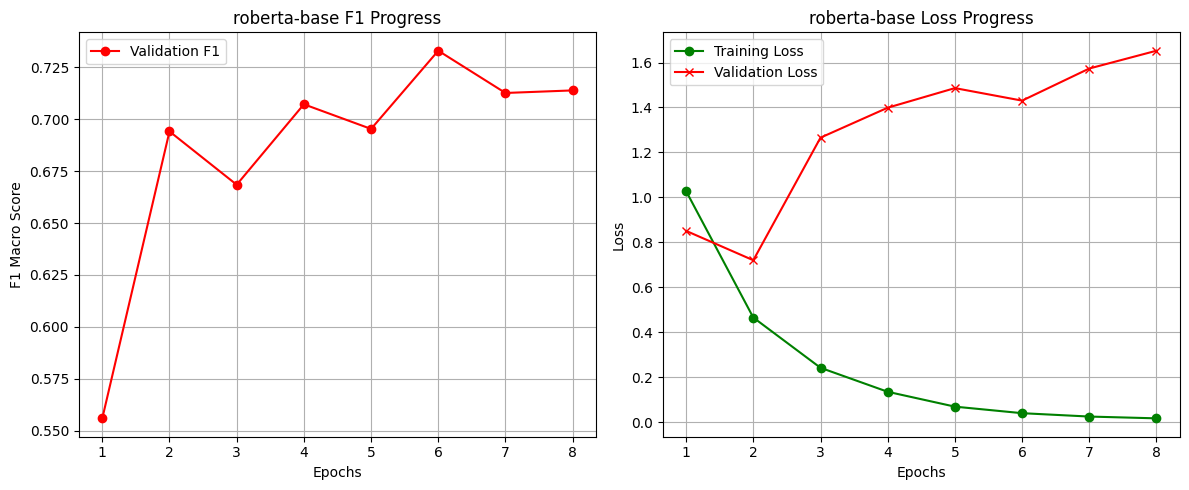

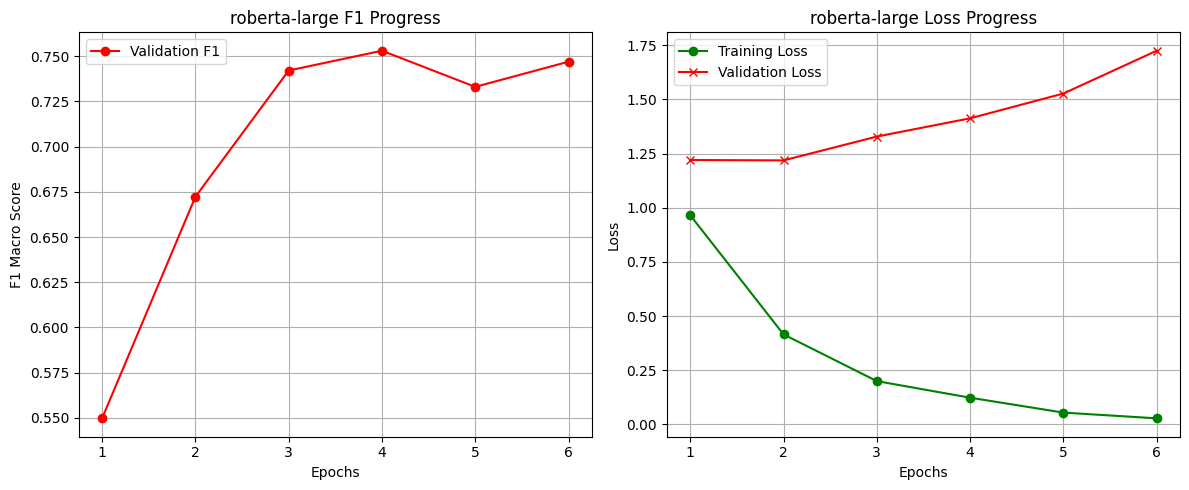

In [103]:
for name, trainer in models.items():
    log_history = trainer.state.log_history

    train_loss = [x['loss'] for x in log_history if 'loss' in x]
    val_loss   = [x['eval_loss'] for x in log_history if 'eval_loss' in x]

    val_f1   = [x['eval_f1_macro'] for x in log_history if 'eval_f1_macro' in x]

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(range(1, len(val_f1)+1), val_f1, label='Validation F1', color='red', marker='o')
    plt.xlabel('Epochs')
    plt.ylabel('F1 Macro Score')
    plt.title(f'{name} F1 Progress')
    plt.legend()
    plt.grid(True)

    plt.subplot(1,2,2)
    plt.plot(range(1, len(train_loss)+1), train_loss, label='Training Loss', color='green', marker='o')
    plt.plot(range(1, len(val_loss)+1), val_loss, label='Validation Loss', color='red', marker='x')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title(f'{name} Loss Progress')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


## 15. RoBERTa Large Confusion Matrix

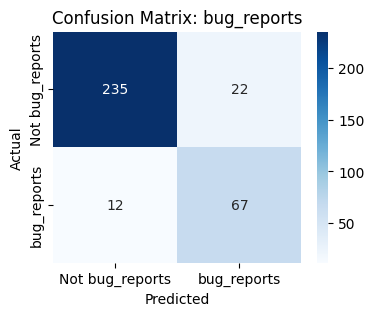

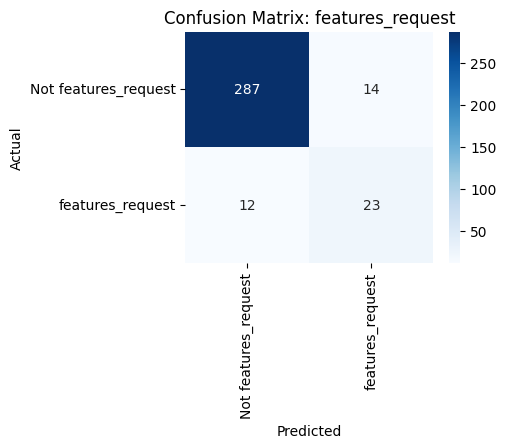

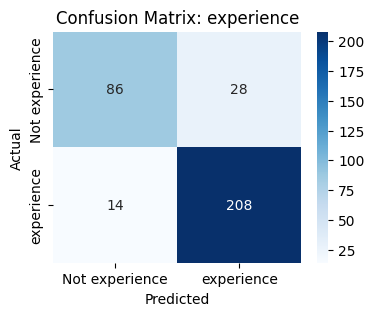

In [104]:
from sklearn.metrics import multilabel_confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


model_name_for_cm = 'roberta-large'
trainer_for_cm = models[model_name_for_cm]


if trainer_for_cm.model.device != trainer_for_cm.args.device:
    trainer_for_cm.model.to(trainer_for_cm.args.device)

output_cm = trainer_for_cm.predict(test_ds_tok[model_name_for_cm])
logits_cm = output_cm.predictions
y_test = np.array(test_df[target_names].values)
probs_cm = sigmoid(logits_cm)
test_preds = (probs_cm >= 0.5).astype(int)

cms = multilabel_confusion_matrix(y_test, test_preds)

for i, label in enumerate(target_names):
    plt.figure(figsize=(4, 3))
    sns.heatmap(cms[i], annot=True, fmt="d", cmap="Blues",
                xticklabels=["Not " + label, label],
                yticklabels=["Not " + label, label])
    plt.title(f"Confusion Matrix: {label}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

## 16. RoBERTa Large Confusion Matrix

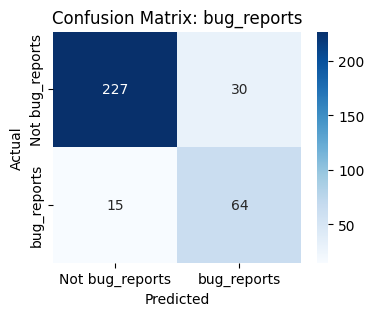

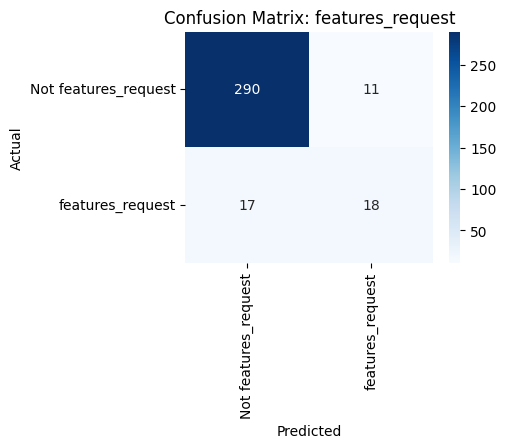

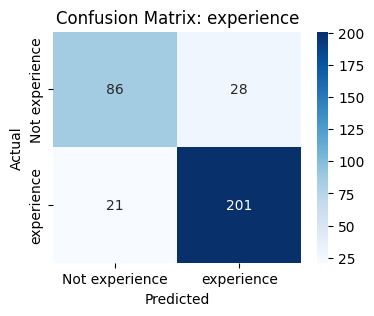

In [105]:
from sklearn.metrics import multilabel_confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


model_name_for_cm = 'roberta-base'
trainer_for_cm = models[model_name_for_cm]


if trainer_for_cm.model.device != trainer_for_cm.args.device:
    trainer_for_cm.model.to(trainer_for_cm.args.device)

output_cm = trainer_for_cm.predict(test_ds_tok[model_name_for_cm])
logits_cm = output_cm.predictions
y_test = np.array(test_df[target_names].values)
probs_cm = sigmoid(logits_cm)
test_preds = (probs_cm >= 0.5).astype(int)

cms = multilabel_confusion_matrix(y_test, test_preds)

for i, label in enumerate(target_names):
    plt.figure(figsize=(4, 3))
    sns.heatmap(cms[i], annot=True, fmt="d", cmap="Blues",
                xticklabels=["Not " + label, label],
                yticklabels=["Not " + label, label])
    plt.title(f"Confusion Matrix: {label}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()